# Machine Learning #11 - Time Series Forecasting📈

Today we will **forecast natural gas consumption in Prague** — how much gas the city
will need in the next hour and during the next 24 hours.



## What is time series forecasting? ⏳

A **time series** is a sequence of measurements taken at regular time steps — here
**one value per hour**. Forecasting means estimating future values from the past ones.

For the simplest case (one hour ahead) we want a function $f$ — our neural network — that
looks at the last $L$ hours and predicts the next one:

$$\hat{y}_{t} = f\big(y_{t-L},\; y_{t-L+1},\; \dots,\; y_{t-1}\big)$$

### Key vocabulary 📖

| Term | Meaning | Today |
|---|---|---|
| **Lookback** (window length) $L$ | how many past steps the model sees | 168 h = 1 week |
| **Horizon** $H$ | how many future steps we predict | 1 h, later 24 h |
| **One-step forecast** | predict only the next value | $H = 1$ |
| **Multi-step forecast** | predict several future values at once | $H = 24$ |
| **Endogenous variable** | the series we forecast; its own past is an input | `Consumption` |
| **Exogenous variables** | external drivers that influence the target | temperature, humidity, calendar |

> 💡 **Why a week?** Gas consumption has a **daily** rhythm (people heat in the morning and
> evening) and a **weekly** rhythm (weekdays vs. weekends). A 168-hour window contains
> both of them.

## Imports and setup

Remember to set a **GPU** runtime in Colab! (*Runtime → Change runtime type → T4 GPU*)

In [1]:
!pip install torchinfo

In [2]:
import copy
import random
import time

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import torchinfo

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

FAST_MODE    = not torch.cuda.is_available()
EPOCHS       = 5 if FAST_MODE else 10
TRAIN_STRIDE = 4 if FAST_MODE else 1     # use every n-th training window
BATCH_SIZE   = 128

print("Device:", device, "| FAST_MODE:", FAST_MODE, "| epochs:", EPOCHS)

Device: cuda | FAST_MODE: False | epochs: 10


## How do we measure a forecast? 📐

We compare the true values $y_i$ with the predictions $\hat{y}_i$ over $n$ test hours.

| Metric | Formula | How to read it |
|---|---|---|
| **MAE** | $$\frac{1}{n}\sum \lvert y_i - \hat{y}_i \rvert$$ | average error in m³ — easy to explain |
| **RMSE** | $\sqrt{\frac{1}{n}\sum (y_i - \hat{y}_i)^2}$ | like MAE, but punishes **large** errors more |
| **MAPE** | $\frac{100}{n}\sum \left\lvert \frac{y_i - \hat{y}_i}{y_i} \right\rvert$ | error in **percent** — comparable across datasets |
| **R²** | $1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$ | 1 = perfect, 0 = no better than the mean |

For MAE, RMSE and MAPE **lower is better**, for R² **higher is better**.

Every model will be stored in a small **leaderboard** 🏆 so we can compare them at the end.

In [4]:
def compute_metrics(y_true, y_pred):
    # Flatten so that the function works for 1-step and for 24-step forecasts
    y_true, y_pred = np.ravel(y_true), np.ravel(y_pred)
    return {
        "MAE":  mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE": np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
        "R2":   r2_score(y_true, y_pred),
    }

leaderboard = {}   # model name -> metrics

def add_to_leaderboard(name, y_true, y_pred):
    leaderboard[name] = compute_metrics(y_true, y_pred)
    return pd.DataFrame(leaderboard[name], index=[name]).round(3)

def show_leaderboard():
    board = pd.DataFrame(leaderboard).T
    board["Horizon"] = np.where(board.index.str.startswith("24h"), "24 h", "1 h")
    # 1-hour models first, then 24-hour models; inside each group sorted by MAE
    return board.sort_values(["Horizon", "MAE"])[["Horizon", "MAE", "RMSE", "MAPE", "R2"]].round(3)

## The dataset ⛽

**Source:** Natural gas forecasting —
a pre-processed version prepared for this course.

- 📍 natural gas distribution network of **Prague** (≈ 423 000 customers in 2018)
- 🗓️ **2013-01-01 → 2018-12-31**, one row per **hour** → **52 584 rows**
- 🌡️ weather from the **Prague airport (LKPR)** weather station (METAR reports)

| Customer group | Share of consumption |
|---|---|
| 🏘️ households | 33.3 % |
| 🏭 large industry | 24.8 % |
| 🏢 medium customers | 18.9 % |
| 🏪 small customers | 21.9 % |
| 🔧 network losses | the rest |

🔥 **Heating season** (Sep 1 – May 31) is responsible for **70–75 %** of the yearly consumption —
so temperature should be a very strong predictor.

### Columns we will use

| Variable | Meaning | Type |
|---|---|---|
| `Consumption` | gas consumption in the hour (m³) | 🎯 target (endogenous) |
| `Temperature` | air temperature (°C) | exogenous |
| `Pressure` | air pressure (mmHg) | exogenous |
| `Humidity` | relative humidity (%) | exogenous |
| `Hour`, `Day`, `Month`, `Day_of_week` | calendar information | exogenous |
| `Holiday` | 1 = public holiday | exogenous |

## Load the data

In [5]:
DATA_URL = "https://raw.githubusercontent.com/rasvob/VSB-FEI-Deep-Learning-Exercises/main/datasets/ppnet_metar_v8.csv"

df = pd.read_csv(DATA_URL, sep=";", index_col=0)
df.index = pd.DatetimeIndex(df.index)      # the index becomes real timestamps

columns = ["Year", "Month", "Day", "Hour", "Day_of_week", "Holiday",
           "Consumption", "Temperature", "Pressure", "Humidity"]
df = df.loc[df.Year < 2019, columns].copy()
df.head()

,Year,Month,Day,Hour,Day_of_week,Holiday,Consumption,Temperature,Pressure,Humidity
Datetime,,,,,,,,,,
2013-01-01 00:00:00,2013,1,1,0,2,0,146584.0,0.0,733.0,87.0
2013-01-01 01:00:00,2013,1,1,1,2,0,149524.0,-1.0,732.2,86.0
2013-01-01 02:00:00,2013,1,1,2,2,0,151388.0,0.0,731.6,87.0
2013-01-01 03:00:00,2013,1,1,3,2,0,152436.0,-1.0,731.5,93.0
2013-01-01 04:00:00,2013,1,1,4,2,0,160176.0,0.0,731.1,87.0


In [6]:
df.shape

(52584, 10)

In [7]:
df.isna().sum()

,0
Year,0
Month,0
Day,0
Hour,0
Day_of_week,0
Holiday,0
Consumption,0
Temperature,0
Pressure,0
Humidity,0


## A quick look at the data 🔎

Before modelling we want to *see* the patterns the network should learn:

1. Is there a **yearly** (seasonal) pattern?
2. Is there a **daily / weekly** pattern?
3. How strongly does **temperature** influence consumption?

The plots are interactive — **zoom in** with the mouse. 🔍

In [8]:
px.line(df, x=df.index, y="Consumption", color="Year",
        title="Hourly gas consumption 2013-2018")

In [9]:
# Zoom: two weeks in January -> daily and weekly rhythm
two_weeks = df.loc["2017-01-09":"2017-01-22"]
px.line(two_weeks, x=two_weeks.index, y="Consumption",
        title="Two weeks of consumption (January 2017)")

In [10]:
# Temperature vs. consumption (every 10th hour, to keep the plot light)
sample = df.iloc[::10]
px.scatter(sample, x="Temperature", y="Consumption", color="Month", opacity=0.5,
           title="The colder it is, the more gas we burn")

> 💡 **What do you see?** Strong **yearly seasonality** (winter peaks), a clear **daily
> cycle**, slightly lower values at weekends, and an almost linear dependence on
> temperature below ≈ 13 °C. Above it the heating is off and consumption stays flat.

## Chronological split ✂️

A random split, common for ordinary tabular data, would be cheating 🚫 for time series: the model would train on Wednesday and Friday and then “predict” Thursday — it would peek into the future.

Instead we split **by time**:

| Set | Years | Purpose |
|---|---|---|
| 🟦 **train** | 2013 – 2016 | learn the weights |
| 🟨 **validation** | 2017 | choose the best epoch |
| 🟥 **test** | 2018 | final, honest evaluation |

```
2013 ──── 2014 ──── 2015 ──── 2016 │ 2017 │ 2018
            train                 │  val │ test     → time
```

In [11]:
# Positions (row numbers) where the validation and the test periods start
train_end = int((df.Year <= 2016).sum())     # first row of 2017
val_end   = int((df.Year <= 2017).sum())     # first row of 2018
n_rows    = len(df)

print(f"train: rows 0 .. {train_end - 1}   ({train_end} hours)")
print(f"val:   rows {train_end} .. {val_end - 1}   ({val_end - train_end} hours)")
print(f"test:  rows {val_end} .. {n_rows - 1}   ({n_rows - val_end} hours)")

train: rows 0 .. 35063   (35064 hours)
val:   rows 35064 .. 43823   (8760 hours)
test:  rows 43824 .. 52583   (8760 hours)


## Baselines first! 📏

Before training anything clever, we ask: **how good is a trivial forecast?**
A neural network is only useful if it **beats** these numbers.

| Baseline | Rule | Idea |
|---|---|---|
| **Naive** | $$\hat{y}_t = y_{t-1}$$ | "the next hour will be like this hour" |
| **Seasonal naive** | $\hat{y}_t = y_{t-24}$ | "the next hour will be like the same hour yesterday" |

They need **no training** and they are surprisingly hard to beat. 😉

In [12]:
consumption = df["Consumption"].values
test_idx_1h = np.arange(val_end, n_rows)          # every hour of 2018
test_times  = df.index[test_idx_1h]

y_test_true = consumption[test_idx_1h]

naive_pred    = consumption[test_idx_1h - 1]      # value one hour earlier
seasonal_pred = consumption[test_idx_1h - 24]     # value 24 hours earlier

add_to_leaderboard("Baseline: naive (t-1)", y_test_true, naive_pred)
add_to_leaderboard("Baseline: seasonal naive (t-24)", y_test_true, seasonal_pred)
show_leaderboard()

,Horizon,MAE,RMSE,MAPE,R2
Baseline: naive (t-1),1 h,5530.338,8501.308,7.037,0.987
Baseline: seasonal naive (t-24),1 h,9026.016,13930.146,9.768,0.965


> 💡 The naive forecast is extremely good for **one hour ahead** — consumption does not
> change much within an hour. Keep these numbers in mind: they are the bar our networks
> have to jump over. 🏋️

## Sliding windows 🪟

A network needs pairs **(input, target)**. We create them by sliding a window over the
series. Toy example: series `0, 1, 2, …, 9`, lookback $L = 3$, horizon $H = 1$:

| Window | Input $X$ (past 3 values) | Target $y$ (next value) |
|---|---|---|
| 1 | `[0, 1, 2]` | `3` |
| 2 | `[1, 2, 3]` | `4` |
| 3 | `[2, 3, 4]` | `5` |
| … | … | … |
| 7 | `[6, 7, 8]` | `9` |

Each window is **one training sample**. For the real data, $L = 168$, so one sample is a
**matrix of 168 rows** (hours) × **number of features** (columns).

### Why not create all windows in advance? 🤔

With 35 000 windows × 168 hours × 13 features we would need **≈ 600 MB** of RAM, while
the original data has only ≈ 3 MB. Every value would be copied 168 times!
PyTorch offers a smarter way: a **`Dataset`** that cuts the window **only when it is
needed**.

### The PyTorch `Dataset` 🧺

Our dataset receives the whole (scaled) table and a list of **target positions** `t`.
For each `t` it returns:

$$x = \text{features}[\,t-L : t\,] \qquad y = \text{target}[\,t : t+H\,]$$

In [13]:
class WindowDataset(Dataset):
    def __init__(self, features, target, target_positions, lookback, horizon=1):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.target   = torch.tensor(target,   dtype=torch.float32)
        self.positions = target_positions   # first predicted row of every window
        self.lookback  = lookback
        self.horizon   = horizon

    def __len__(self):
        return len(self.positions)

    def __getitem__(self, i):
        t = self.positions[i]
        x = self.features[t - self.lookback : t]   # (lookback, n_features)  -> the past
        y = self.target[t : t + self.horizon]      # (horizon,)              -> the future
        return x, y

In [14]:
toy = np.arange(10, dtype=np.float32)
toy_ds = WindowDataset(features=toy.reshape(-1, 1), target=toy,
                       target_positions=np.arange(3, 10), lookback=3)

print("number of windows:", len(toy_ds))
for i in range(3):
    x, y = toy_ds[i]
    print(f"window {i}: x = {x.ravel().tolist()} -> y = {y.tolist()}")

number of windows: 7
window 0: x = [0.0, 1.0, 2.0] -> y = [3.0]
window 1: x = [1.0, 2.0, 3.0] -> y = [4.0]
window 2: x = [2.0, 3.0, 4.0] -> y = [5.0]


### The `DataLoader` 🚚

Pushing the whole training set through the network in one step is fine for small datasets. We have ~35 000 large samples, so we use mini-batches: the DataLoader takes e.g. 128 windows, stacks them into one tensor and hands them to the network.


> ⚠️ **Shuffling windows is OK!** We do not shuffle the hours *inside* a window — every
> window keeps its internal time order. We only change the order in which whole windows
> are shown to the network. Validation and test windows are **not** shuffled.

### Putting it together: `prepare_data` 🛠️

The function below does everything we need for any experiment:

1. **scales** the inputs and the target with `StandardScaler` — fitted **only on the
   training years** (no information leak from the future):
   $$z = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$
2. computes the **target positions** for train / validation / test,
3. builds three `WindowDataset`s and three `DataLoader`s.

> 💡 The first validation window uses the last week of 2016 as its input. That is fine —
> it is the **past**, which we would know in reality. Only the *targets* must belong to
> the right period.

We will call this function again in the activities with other features, lookbacks and
horizons. 🔁

In [15]:
def prepare_data(feature_cols, lookback=168, horizon=1, batch_size=BATCH_SIZE):
    # 1) Scaling - fit ONLY on the training rows
    feature_scaler = StandardScaler().fit(df[feature_cols].iloc[:train_end])
    target_scaler  = StandardScaler().fit(df[["Consumption"]].iloc[:train_end])

    features = feature_scaler.transform(df[feature_cols])
    target   = target_scaler.transform(df[["Consumption"]]).ravel()

    # 2) Target positions: the window [t, t + horizon) must lie inside its period
    train_pos = np.arange(lookback, train_end - horizon + 1)[::TRAIN_STRIDE]
    val_pos   = np.arange(train_end, val_end - horizon + 1)[::TRAIN_STRIDE]
    test_pos  = np.arange(val_end,   n_rows  - horizon + 1)   # always the full test year

    # 3) Datasets and DataLoaders
    make_ds = lambda pos: WindowDataset(features, target, pos, lookback, horizon)
    data = {
        "train": DataLoader(make_ds(train_pos), batch_size=batch_size, shuffle=True),
        "val":   DataLoader(make_ds(val_pos),   batch_size=batch_size, shuffle=False),
        "test":  DataLoader(make_ds(test_pos),  batch_size=batch_size, shuffle=False),
        "test_pos": test_pos,
        "target_scaler": target_scaler,
        "n_features": len(feature_cols),
        "lookback": lookback,
        "horizon": horizon,
    }
    print(f"train windows: {len(train_pos)} | val windows: {len(val_pos)} | test windows: {len(test_pos)}")
    return data

We start with the simplest setting: **only the consumption itself** as input
(a *univariate* forecast), one week of history, one hour ahead.

In [16]:
data_uni = prepare_data(feature_cols=["Consumption"], lookback=168, horizon=1)

x_batch, y_batch = next(iter(data_uni["train"]))
print("x batch:", tuple(x_batch.shape), " -> (batch, time steps, features)")
print("y batch:", tuple(y_batch.shape), "     -> (batch, horizon)")

train windows: 34896 | val windows: 8760 | test windows: 8760
x batch: (128, 168, 1)  -> (batch, time steps, features)
y batch: (128, 1)      -> (batch, horizon)


## The training loop  🔁



The loss is the **mean squared error** (MSE), the classic loss for regression:

$$L = \frac{1}{n}\sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

Because we will train several models, we wrap the loop in a **function** once and reuse it.

In [17]:
def train_model(model, data, epochs=EPOCHS, lr=1e-3, clip_value=1.0):
    model = model.to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)

    history = {"train_loss": [], "val_loss": []}
    best_val_loss, best_weights = float("inf"), None

    for epoch in range(epochs):
        start = time.time()

        # ---- training ----
        model.train()
        train_loss = 0.0
        for xb, yb in data["train"]:
            xb, yb = xb.to(device), yb.to(device)
            loss = criterion(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), clip_value)
            optimizer.step()
            train_loss += loss.item() * len(xb)
        train_loss /= len(data["train"].dataset)

        # ---- validation ----
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for xb, yb in data["val"]:
                xb, yb = xb.to(device), yb.to(device)
                val_loss += criterion(model(xb), yb).item() * len(xb)
        val_loss /= len(data["val"].dataset)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())

        print(f"epoch {epoch + 1:2d}/{epochs} | train {train_loss:.4f} | "
              f"val {val_loss:.4f} | {time.time() - start:.1f}s")

    model.load_state_dict(best_weights)
    print(f"✅ best validation loss: {best_val_loss:.4f}")
    return history


def plot_history(history, title="Training history"):
    plt.figure(figsize=(6, 3.5))
    plt.plot(history["train_loss"], marker="o", label="train loss")
    plt.plot(history["val_loss"],   marker="o", label="validation loss")
    plt.xlabel("Epoch"); plt.ylabel("MSE (scaled)"); plt.title(title)
    plt.legend(); plt.tight_layout(); plt.show()

### Prediction and evaluation 🔮

After training we predict the whole test year and **undo the scaling** with
`inverse_transform`, so the numbers are again in m³ and comparable with the baselines.

In [18]:
def predict(model, data):
    # Returns true values and predictions in ORIGINAL units, shape (n_windows, horizon)
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for xb, yb in data["test"]:
            preds.append(model(xb.to(device)).cpu().numpy())
            trues.append(yb.numpy())
    scaler = data["target_scaler"]
    inverse = lambda a: scaler.inverse_transform(a.reshape(-1, 1)).reshape(a.shape)
    return inverse(np.concatenate(trues)), inverse(np.concatenate(preds))


def plot_forecast(times, y_true, y_pred, title):
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=times, y=y_true, name="actual", line=dict(width=1)))
    fig.add_trace(go.Scatter(x=times, y=y_pred, name="predicted", line=dict(width=1)))
    fig.update_layout(title=title, xaxis_title="Time", yaxis_title="Consumption (m³)")
    fig.show()

## Model 1 — LSTM 🧠


In [19]:
class LSTMForecaster(nn.Module):
    def __init__(self, n_features, hidden_size=64, num_layers=1, horizon=1, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_features, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_size, horizon)

    def forward(self, x):                   # x: (batch, time, features)
        output, (h_n, c_n) = self.lstm(x)   # output: (batch, time, hidden)
        last = output[:, -1, :]             # state after the last hour: (batch, hidden)
        return self.head(self.dropout(last))   # (batch, horizon)

In [20]:
set_seed()
lstm_uni = LSTMForecaster(n_features=data_uni["n_features"])
torchinfo.summary(lstm_uni, input_size=(1, 168, data_uni["n_features"]))

Layer (type:depth-idx)                   Output Shape              Param #
LSTMForecaster                           [1, 1]                    --
├─LSTM: 1-1                              [1, 168, 64]              17,152
├─Dropout: 1-2                           [1, 64]                   --
├─Linear: 1-3                            [1, 1]                    65
Total params: 17,217
Trainable params: 17,217
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 2.88
Input size (MB): 0.00
Forward/backward pass size (MB): 0.09
Params size (MB): 0.07
Estimated Total Size (MB): 0.16

epoch  1/10 | train 0.1364 | val 0.0624 | 1.6s
epoch  2/10 | train 0.0415 | val 0.0194 | 1.1s
epoch  3/10 | train 0.0212 | val 0.0129 | 1.1s
epoch  4/10 | train 0.0167 | val 0.0103 | 1.1s
epoch  5/10 | train 0.0144 | val 0.0073 | 4.4s
epoch  6/10 | train 0.0125 | val 0.0062 | 2.0s
epoch  7/10 | train 0.0120 | val 0.0068 | 1.9s
epoch  8/10 | train 0.0113 | val 0.0066 | 2.7s
epoch  9/10 | train 0.0110 | val 0.0056 | 1.9s
epoch 10/10 | train 0.0107 | val 0.0051 | 1.2s
✅ best validation loss: 0.0051


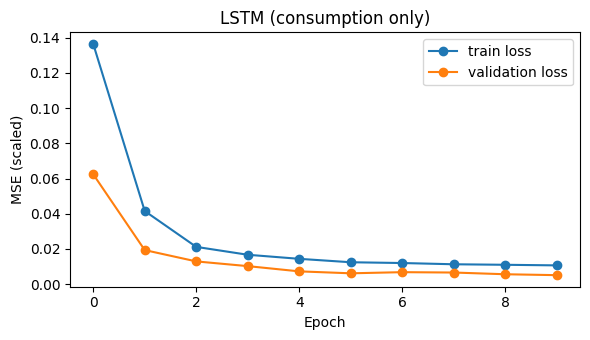

In [21]:
history = train_model(lstm_uni, data_uni)
plot_history(history, "LSTM (consumption only)")

In [22]:
y_true, y_pred = predict(lstm_uni, data_uni)
add_to_leaderboard("LSTM (consumption only)", y_true, y_pred)

,MAE,RMSE,MAPE,R2
LSTM (consumption only),3255.327,4641.004,4.893,0.996


In [23]:
plot_forecast(test_times, y_true.ravel(), y_pred.ravel(), "LSTM: actual vs. predicted (2018)")

> 💡 **Zoom into a single week.** Does the prediction follow the daily cycle? Is it
> shifted to the right? A forecast that is just the **previous value shifted by one hour**
> looks good from far away, but it is no better than the naive baseline!

## Model 2 — 1D Convolutional network 🌀

A **1D convolution** slides a small filter (e.g. 5 hours long) **along the time axis** and
looks for local patterns such as *"morning ramp-up"* or *"night drop"*. It is the same idea
as image convolutions, just in one dimension.

**Dilation** 🕳️ inserts gaps between the filter's taps, so the filter sees a longer
period with the same number of weights:

```
dilation = 1:   ■ ■ ■ ■ ■            covers 5 hours
dilation = 2:   ■ · ■ · ■ · ■ · ■    covers 9 hours
```

### PyTorch detail: the channel dimension ⚠️

`nn.Conv1d` expects **(batch, channels, time)**, but our windows are
**(batch, time, features)**. We swap the two axes with
`x.permute(0, 2, 1)` — features become channels.

To know how big the final `nn.Linear` layer must be, we push one **dummy window**
through the convolutional part in `__init__` and count the outputs — a common
PyTorch trick.

In [24]:
class CNNForecaster(nn.Module):
    def __init__(self, n_features, lookback, channels=64, horizon=1, dropout=0.2):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(n_features, channels, kernel_size=5, dilation=2), nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(channels, channels, kernel_size=3, dilation=2), nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Flatten(),
        )
        # Dummy forward pass -> size of the flattened output
        with torch.no_grad():
            n_flat = self.conv(torch.zeros(1, n_features, lookback)).shape[1]

        self.head = nn.Sequential(
            nn.Linear(n_flat, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, horizon),
        )

    def forward(self, x):            # x: (batch, time, features)
        x = x.permute(0, 2, 1)       # -> (batch, features, time) for Conv1d
        return self.head(self.conv(x))

In [25]:
set_seed()
cnn_uni = CNNForecaster(n_features=data_uni["n_features"], lookback=168)
torchinfo.summary(cnn_uni, input_size=(1, 168, data_uni["n_features"]))

Layer (type:depth-idx)                   Output Shape              Param #
CNNForecaster                            [1, 1]                    --
├─Sequential: 1-1                        [1, 2432]                 --
│    └─Conv1d: 2-1                       [1, 64, 160]              384
│    └─ReLU: 2-2                         [1, 64, 160]              --
│    └─MaxPool1d: 2-3                    [1, 64, 80]               --
│    └─Conv1d: 2-4                       [1, 64, 76]               12,352
│    └─ReLU: 2-5                         [1, 64, 76]               --
│    └─MaxPool1d: 2-6                    [1, 64, 38]               --
│    └─Flatten: 2-7                      [1, 2432]                 --
├─Sequential: 1-2                        [1, 1]                    --
│    └─Linear: 2-8                       [1, 64]                   155,712
│    └─ReLU: 2-9                         [1, 64]                   --
│    └─Dropout: 2-10                     [1, 64]                   --
│    

epoch  1/10 | train 0.0557 | val 0.0167 | 2.7s
epoch  2/10 | train 0.0253 | val 0.0113 | 1.7s
epoch  3/10 | train 0.0217 | val 0.0106 | 1.6s
epoch  4/10 | train 0.0203 | val 0.0101 | 1.7s
epoch  5/10 | train 0.0203 | val 0.0188 | 1.1s
epoch  6/10 | train 0.0195 | val 0.0077 | 1.1s
epoch  7/10 | train 0.0189 | val 0.0076 | 1.1s
epoch  8/10 | train 0.0187 | val 0.0073 | 1.2s
epoch  9/10 | train 0.0186 | val 0.0070 | 1.3s
epoch 10/10 | train 0.0174 | val 0.0066 | 1.3s
✅ best validation loss: 0.0066


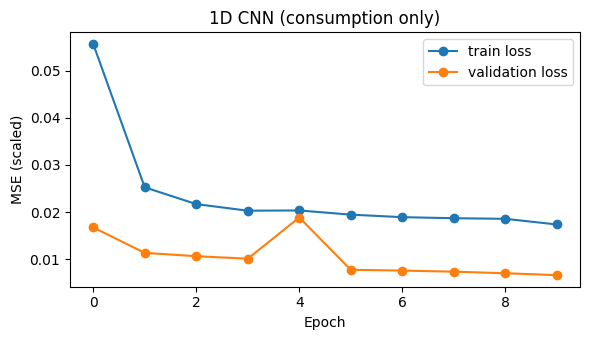

,Horizon,MAE,RMSE,MAPE,R2
LSTM (consumption only),1 h,3255.327,4641.004,4.893,0.996
CNN (consumption only),1 h,3383.885,5053.129,4.268,0.995
Baseline: naive (t-1),1 h,5530.338,8501.308,7.037,0.987
Baseline: seasonal naive (t-24),1 h,9026.016,13930.146,9.768,0.965


In [26]:
history = train_model(cnn_uni, data_uni)
plot_history(history, "1D CNN (consumption only)")

y_true, y_pred = predict(cnn_uni, data_uni)
add_to_leaderboard("CNN (consumption only)", y_true, y_pred)
show_leaderboard()

## Adding exogenous variables 🌡️📅

So far the network only knew the past consumption. But we know much more: the
**temperature**, the **hour**, the **day of the week**, **holidays**… Let's give it to the network.

### Cyclical encoding of time 🕐

Hours go `0, 1, …, 23, 0, 1, …`. As plain numbers, **23** and **0** look far apart, although
they are neighbours. We therefore put time on a **circle** using sine and cosine:

$$\text{Hour}_{\sin} = \sin\!\left(\frac{2\pi \cdot \text{Hour}}{24}\right) \qquad
\text{Hour}_{\cos} = \cos\!\left(\frac{2\pi \cdot \text{Hour}}{24}\right)$$

| Hour | Plain value | (sin, cos) |
|---|---|---|
| 0 | 0 | (0.00, 1.00) |
| 6 | 6 | (1.00, 0.00) |
| 12 | 12 | (0.00, −1.00) |
| 23 | 23 | (−0.26, 0.97) ← close to hour 0 ✅ |

We need **both** sine and cosine — with sine alone, e.g. 3 h and 9 h would get the same
value (0.71). The same trick is used for the day of the week (period 7), the day of the
month (31) and the month (12).

In [27]:
def add_cyclical(df, column, period):
    df[f"{column}_sin"] = np.sin(2 * np.pi * df[column] / period)
    df[f"{column}_cos"] = np.cos(2 * np.pi * df[column] / period)

add_cyclical(df, "Hour", 24)
add_cyclical(df, "Day_of_week", 7)
add_cyclical(df, "Day", 31)
add_cyclical(df, "Month", 12)

df[["Hour", "Hour_sin", "Hour_cos"]].head(4)

,Hour,Hour_sin,Hour_cos
Datetime,,,
2013-01-01 00:00:00,0,0.000000,1.000000
2013-01-01 01:00:00,1,0.258819,0.965926
2013-01-01 02:00:00,2,0.500000,0.866025
2013-01-01 03:00:00,3,0.707107,0.707107


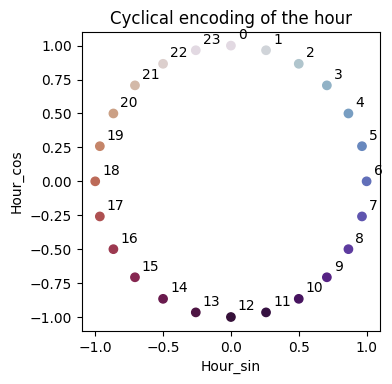

In [28]:
# Hours on a circle: 23 h ends up right next to 0 h
hours = df.iloc[:24]
plt.figure(figsize=(4, 4))
plt.scatter(hours["Hour_sin"], hours["Hour_cos"], c=hours["Hour"], cmap="twilight")
for _, row in hours.iterrows():
    plt.annotate(int(row["Hour"]), (row["Hour_sin"], row["Hour_cos"]),
                 textcoords="offset points", xytext=(5, 5))
plt.gca().set_aspect("equal"); plt.title("Cyclical encoding of the hour")
plt.xlabel("Hour_sin"); plt.ylabel("Hour_cos"); plt.tight_layout(); plt.show()

Now we just call `prepare_data` with **13 input columns** instead of 1. The model class
stays the same — only `n_features` changes. 🎉

In [29]:
FEATURES = ["Consumption", "Temperature", "Pressure", "Humidity", "Holiday",
            "Hour_sin", "Hour_cos", "Day_of_week_sin", "Day_of_week_cos",
            "Day_sin", "Day_cos", "Month_sin", "Month_cos"]

data_exo = prepare_data(feature_cols=FEATURES, lookback=168, horizon=1)
print("number of input features:", data_exo["n_features"])

train windows: 34896 | val windows: 8760 | test windows: 8760
number of input features: 13


epoch  1/10 | train 0.1032 | val 0.0225 | 1.3s
epoch  2/10 | train 0.0206 | val 0.0133 | 1.4s
epoch  3/10 | train 0.0166 | val 0.0100 | 1.3s
epoch  4/10 | train 0.0145 | val 0.0085 | 1.3s
epoch  5/10 | train 0.0133 | val 0.0082 | 1.3s
epoch  6/10 | train 0.0123 | val 0.0076 | 1.3s
epoch  7/10 | train 0.0116 | val 0.0063 | 1.6s
epoch  8/10 | train 0.0108 | val 0.0057 | 1.7s
epoch  9/10 | train 0.0105 | val 0.0052 | 1.4s
epoch 10/10 | train 0.0098 | val 0.0051 | 1.3s
✅ best validation loss: 0.0051


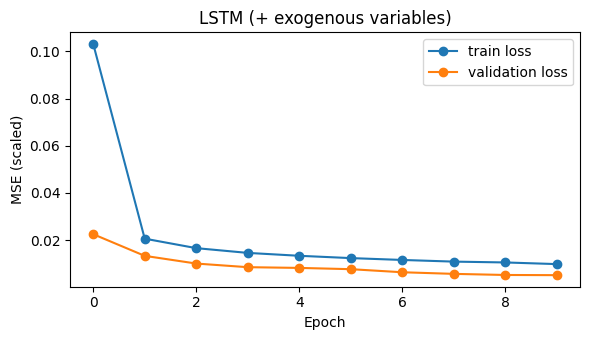

,Horizon,MAE,RMSE,MAPE,R2
LSTM (consumption only),1 h,3255.327,4641.004,4.893,0.996
CNN (consumption only),1 h,3383.885,5053.129,4.268,0.995
LSTM (+ exogenous),1 h,3490.275,4699.095,6.253,0.996
Baseline: naive (t-1),1 h,5530.338,8501.308,7.037,0.987
Baseline: seasonal naive (t-24),1 h,9026.016,13930.146,9.768,0.965


In [30]:
set_seed()
lstm_exo = LSTMForecaster(n_features=data_exo["n_features"])
history = train_model(lstm_exo, data_exo)
plot_history(history, "LSTM (+ exogenous variables)")

y_true, y_pred = predict(lstm_exo, data_exo)
add_to_leaderboard("LSTM (+ exogenous)", y_true, y_pred)
show_leaderboard()

## Model 3 — Transformer 🤖

The LSTM reads the week **step by step**, so information from 160 hours ago must travel
through 160 updates of the memory. The **Transformer** takes a different approach:
**every hour can look directly at every other hour** in the window and decide which ones
are important. This mechanism is called **self-attention**.

### Self-attention in one picture 👀

For every hour the model creates three vectors:

| Vector | Question it answers |
|---|---|
| **Query** $Q$ | "What am I looking for?" |
| **Key** $K$ | "What do I contain?" |
| **Value** $V$ | "What information do I pass on?" |

The similarity of a query with all keys says **how much attention** an hour pays to the
others; the result is a weighted mix of their values:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d}}\right) V$$

*Example:* to predict Monday 7:00, attention may focus on **yesterday 7:00** and
**last Monday 7:00** — without walking through all hours in between.

**Multi-head** attention runs several attentions in parallel (`nhead=4`), so different
heads can learn different relations.

### Positional encoding 📍

Attention itself **does not know the order** of the hours — for it, the window is just a
*set*. We therefore add to every hour a unique "time stamp" made of sine waves of
different frequencies:

$$PE_{(pos,\,2i)} = \sin\!\left(\frac{pos}{10000^{2i/d}}\right) \qquad
PE_{(pos,\,2i+1)} = \cos\!\left(\frac{pos}{10000^{2i/d}}\right)$$

### Our architecture 🏗️

```
input (batch, 168, 13)
   → Linear: 13 → d_model = 32             (project features to the model size)
   → + positional encoding                  (add the order)
   → 2 × TransformerEncoderLayer            (self-attention + small feed-forward net)
   → take the last time step (batch, 32)
   → Linear: 32 → horizon                   (the forecast)
```


In [31]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=1000):
        super().__init__()
        position = torch.arange(max_len).unsqueeze(1)                  # (max_len, 1)
        div_term = torch.exp(torch.arange(0, d_model, 2) * (-np.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)                    # even dimensions
        pe[:, 1::2] = torch.cos(position * div_term)                    # odd dimensions
        # register_buffer: part of the model (saved, moved to GPU), but NOT trained
        self.register_buffer("pe", pe.unsqueeze(0))                     # (1, max_len, d_model)

    def forward(self, x):                         # x: (batch, time, d_model)
        return x + self.pe[:, : x.size(1)]

In [32]:
class TransformerForecaster(nn.Module):
    def __init__(self, n_features, d_model=32, nhead=4, num_layers=2,
                 dim_feedforward=64, dropout=0.1, horizon=1):
        super().__init__()
        self.input_proj = nn.Linear(n_features, d_model)
        self.pos_encoding = PositionalEncoding(d_model)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_feedforward,
            dropout=dropout, batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers,
                                             enable_nested_tensor=False)
        self.head = nn.Linear(d_model, horizon)

    def forward(self, x):                         # x: (batch, time, features)
        z = self.pos_encoding(self.input_proj(x)) # (batch, time, d_model)
        z = self.encoder(z)                       # every hour attends to all other hours
        return self.head(z[:, -1, :])             # last time step -> forecast

In [33]:
set_seed()
transformer_exo = TransformerForecaster(n_features=data_exo["n_features"])
torchinfo.summary(transformer_exo, input_size=(1, 168, data_exo["n_features"]))

Layer (type:depth-idx)                        Output Shape              Param #
TransformerForecaster                         [1, 1]                    --
├─Linear: 1-1                                 [1, 168, 32]              448
├─PositionalEncoding: 1-2                     [1, 168, 32]              --
├─TransformerEncoder: 1-3                     [1, 168, 32]              --
│    └─ModuleList: 2-1                        --                        --
│    │    └─TransformerEncoderLayer: 3-1      [1, 168, 32]              8,544
│    │    └─TransformerEncoderLayer: 3-2      [1, 168, 32]              8,544
├─Linear: 1-4                                 [1, 1]                    33
Total params: 17,569
Trainable params: 17,569
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.01
Input size (MB): 0.01
Forward/backward pass size (MB): 0.47
Params size (MB): 0.04
Estimated Total Size (MB): 0.52

epoch  1/10 | train 0.0695 | val 0.0089 | 5.2s
epoch  2/10 | train 0.0106 | val 0.0067 | 5.4s
epoch  3/10 | train 0.0083 | val 0.0056 | 5.7s
epoch  4/10 | train 0.0069 | val 0.0052 | 7.2s
epoch  5/10 | train 0.0061 | val 0.0044 | 5.5s
epoch  6/10 | train 0.0056 | val 0.0049 | 5.8s
epoch  7/10 | train 0.0054 | val 0.0040 | 5.5s
epoch  8/10 | train 0.0050 | val 0.0043 | 5.5s
epoch  9/10 | train 0.0048 | val 0.0043 | 5.6s
epoch 10/10 | train 0.0047 | val 0.0043 | 5.6s
✅ best validation loss: 0.0040


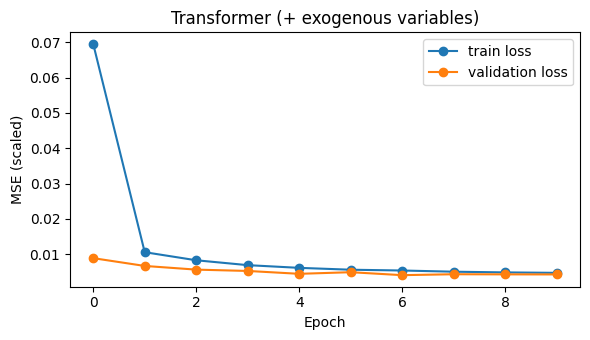

,Horizon,MAE,RMSE,MAPE,R2
Transformer (+ exogenous),1 h,2765.098,4111.679,3.866,0.997
LSTM (consumption only),1 h,3255.327,4641.004,4.893,0.996
CNN (consumption only),1 h,3383.885,5053.129,4.268,0.995
LSTM (+ exogenous),1 h,3490.275,4699.095,6.253,0.996
Baseline: naive (t-1),1 h,5530.338,8501.308,7.037,0.987
Baseline: seasonal naive (t-24),1 h,9026.016,13930.146,9.768,0.965


In [34]:
history = train_model(transformer_exo, data_exo)
plot_history(history, "Transformer (+ exogenous variables)")

y_true, y_pred = predict(transformer_exo, data_exo)
add_to_leaderboard("Transformer (+ exogenous)", y_true, y_pred)
show_leaderboard()

## Forecasting 24 hours at once 🔮

A gas company has to plan **the whole next day**, not just the next hour. There are two
strategies for a multi-step forecast:

| Strategy | How | ➕ | ➖ |
|---|---|---|---|
| **Recursive** | predict 1 h, feed it back as input, repeat 24× | one simple model | errors **accumulate** |
| **Direct (multi-output)** | the network outputs **24 numbers** at once | no feedback loop, fast | bigger output layer |

We use the **direct** strategy. In our code this means just one change: `horizon=24`.
The target $y$ is now a vector:

$$\big(\hat{y}_{t},\; \hat{y}_{t+1},\; \dots,\; \hat{y}_{t+23}\big) = f\big(\text{last 168 hours}\big)$$

The fair baseline for a whole day is the **seasonal naive** forecast:
*"tomorrow will look exactly like today"*.

In [35]:
HORIZON = 24
data_24h = prepare_data(feature_cols=FEATURES, lookback=168, horizon=HORIZON)

# Seasonal-naive baseline for every test window: the 24 hours just before t
test_pos_24 = data_24h["test_pos"]
steps = np.arange(HORIZON)
y_true_24     = consumption[test_pos_24[:, None] + steps]          # (n_windows, 24)
y_seasonal_24 = consumption[test_pos_24[:, None] + steps - 24]

add_to_leaderboard("24h | Baseline: seasonal naive", y_true_24, y_seasonal_24)

train windows: 34873 | val windows: 8737 | test windows: 8737


,MAE,RMSE,MAPE,R2
24h | Baseline: seasonal naive,9025.807,13935.805,9.778,0.965


epoch  1/10 | train 0.1766 | val 0.0736 | 1.3s
epoch  2/10 | train 0.0561 | val 0.0393 | 1.6s
epoch  3/10 | train 0.0423 | val 0.0358 | 1.6s
epoch  4/10 | train 0.0384 | val 0.0365 | 1.2s
epoch  5/10 | train 0.0361 | val 0.0352 | 1.3s
epoch  6/10 | train 0.0344 | val 0.0335 | 1.3s
epoch  7/10 | train 0.0338 | val 0.0328 | 1.3s
epoch  8/10 | train 0.0330 | val 0.0353 | 1.3s
epoch  9/10 | train 0.0322 | val 0.0339 | 1.6s
epoch 10/10 | train 0.0315 | val 0.0358 | 4.0s
✅ best validation loss: 0.0328


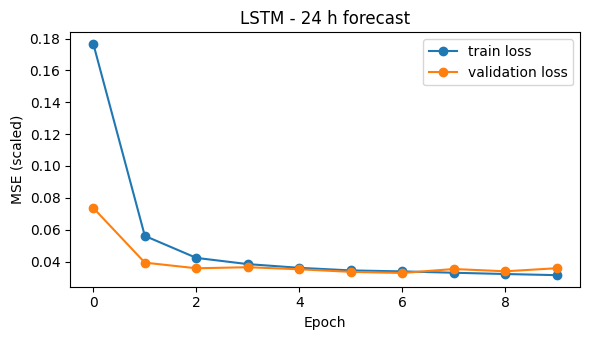

,MAE,RMSE,MAPE,R2
24h | LSTM (+ exogenous),7702.4,11369.827,9.439,0.977


In [36]:
set_seed()
lstm_24h = LSTMForecaster(n_features=data_24h["n_features"], horizon=HORIZON)
history = train_model(lstm_24h, data_24h)
plot_history(history, "LSTM - 24 h forecast")

y_true_24, y_pred_24 = predict(lstm_24h, data_24h)
add_to_leaderboard("24h | LSTM (+ exogenous)", y_true_24, y_pred_24)

### How does the error grow with the horizon? 📉

Predicting the next hour is easier than predicting 23 hours ahead. Let's compute the MAE
**separately for each step** of the horizon and compare it with the baseline.

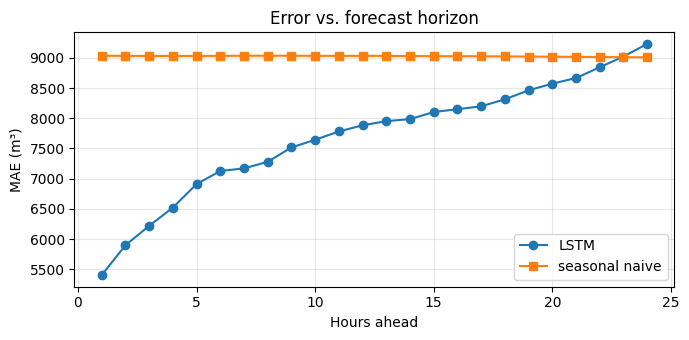

In [37]:
mae_lstm     = np.abs(y_true_24 - y_pred_24).mean(axis=0)       # MAE for each step
mae_seasonal = np.abs(y_true_24 - y_seasonal_24).mean(axis=0)

plt.figure(figsize=(7, 3.5))
plt.plot(steps + 1, mae_lstm, marker="o", label="LSTM")
plt.plot(steps + 1, mae_seasonal, marker="s", label="seasonal naive")
plt.xlabel("Hours ahead"); plt.ylabel("MAE (m³)")
plt.title("Error vs. forecast horizon")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### Day-ahead forecasts in practice 📆

In reality the forecast for the next day is made **once a day, at midnight**. We take only
the windows that start at 0:00 and glue their 24-hour forecasts together.

In [38]:
midnight = df.index[test_pos_24].hour == 0                       # windows starting at 0:00
times_day_ahead = df.index[(test_pos_24[midnight][:, None] + steps).ravel()]

plot_forecast(times_day_ahead, y_true_24[midnight].ravel(), y_pred_24[midnight].ravel(),
              "LSTM: day-ahead forecasts issued at midnight (2018)")

## Leaderboard 🏆

Let's put all the models side by side. Rows starting with **"24h |"** are evaluated on a
harder task (all 24 hours ahead), so compare them **only with each other**.

In [39]:
show_leaderboard()

,Horizon,MAE,RMSE,MAPE,R2
Transformer (+ exogenous),1 h,2765.098,4111.679,3.866,0.997
LSTM (consumption only),1 h,3255.327,4641.004,4.893,0.996
CNN (consumption only),1 h,3383.885,5053.129,4.268,0.995
LSTM (+ exogenous),1 h,3490.275,4699.095,6.253,0.996
Baseline: naive (t-1),1 h,5530.338,8501.308,7.037,0.987
Baseline: seasonal naive (t-24),1 h,9026.016,13930.146,9.768,0.965
24h | LSTM (+ exogenous),24 h,7702.400,11369.827,9.439,0.977
24h | Baseline: seasonal naive,24 h,9025.807,13935.805,9.778,0.965


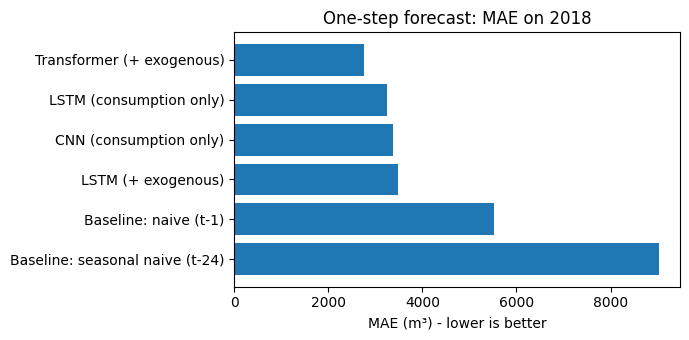

In [40]:
board = show_leaderboard()
one_step = board[~board.index.str.startswith("24h")]

plt.figure(figsize=(7, 3.5))
plt.barh(one_step.index, one_step["MAE"])
plt.gca().invert_yaxis()
plt.xlabel("MAE (m³) - lower is better"); plt.title("One-step forecast: MAE on 2018")
plt.tight_layout(); plt.show()

# Activities ✏️

Now it is your turn to change the code. All the helper functions (`prepare_data`,
`train_model`, `predict`, `add_to_leaderboard`, `show_leaderboard`) are ready to be reused.

## Activity 1 — How much history does the model need? 🪟

We used a lookback of **168 hours** (one week). Train the `LSTMForecaster` with the
exogenous features and lookbacks of **24**, **72** and **336** hours.

- Which lookback gives the lowest MAE?
- How does the **training time** per epoch change? Why?


## Activity 2 — Beat the baseline: swap LSTM for GRU 🔁

A **GRU** is a simpler cousin of the LSTM with fewer gates and
fewer parameters. Create a class `GRUForecaster` by copying `LSTMForecaster` and replacing
`nn.LSTM` with `nn.GRU`.


Then try at least one more change, e.g. `num_layers=2` or `hidden_size=128`.
Add your models to the leaderboard. Did you beat the naive baseline?

## Activity 3 — Which feature matters? 🔍

Find out which exogenous variables actually help. Remove features from `FEATURES`
and retrain the same model (this is called an **ablation study**). Try at least:

1. **without** `Temperature`,
2. **without** all calendar features (`*_sin`, `*_cos`, `Holiday`).

Which removal hurts the most? Does it match what you saw in the scatter plot of
temperature vs. consumption?

## Activity 4 — 24-hour forecast with another architecture 🔮

Train the **CNN** or the **Transformer** on `data_24h` (do not forget `horizon=HORIZON`;
the CNN also needs `lookback=168`).

- Plot its **error vs. horizon** curve together with the LSTM and the seasonal naive
  baseline.
- Which model is best for the **first** hours, and which one for the **last** hours of the day?